# 01 · Black-Scholes et les cinq grecques

> 📘 Notebook compagnon du cours [Les grecques en finance](https://pgu.github.io/pi-gamma-upsilon/). Le code Python reproduit ce que font les playgrounds du site, avec les **mêmes conventions de desk** : vega par point de vol, theta par jour, rho par point de taux.
>
> **Installation** (une fois) : `pip install -r requirements.txt`, puis `jupyter lab`. Lance ce notebook depuis le dossier `notebooks/`.

**Leçons liées :** « D'où viennent les grecques ? », Delta, Gamma, Vega, Theta, Rho.

**Objectifs :** pricer un call et un put, calculer les grecques, les **vérifier par différences finies** (c'est la meilleure façon de ne pas se tromper de signe ou d'unité), puis tracer leurs courbes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import greeks as g          # notre petite bibliothèque (voir greeks.py)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

## 1. Le prix

Cinq inputs : spot `S`, strike `K`, maturité `T` (en années), taux `r`, volatilité `sigma`. Ici un call et un put 5 % OTM à 60 jours.

In [2]:
P = dict(S=100, K=105, T=60/365, r=0.03, sigma=0.25)

call = float(g.price(**P, kind="call"))
put = float(g.price(**P, kind="put"))
pd.DataFrame({
    "prix": [call, put],
    "valeur intrinsèque": [max(P["S"] - P["K"], 0), max(P["K"] - P["S"], 0)],
}, index=["call", "put"]).assign(**{"time value": lambda d: d["prix"] - d["valeur intrinsèque"]})

,prix,valeur intrinsèque,time value
call,2.2714,0,2.2714
put,6.7549,5,1.7549


**Parité call-put** : `C − P = S − K·e^(−rT)`. C'est un contrôle de cohérence à connaître par cœur.

In [3]:
lhs = call - put
rhs = P["S"] - P["K"] * np.exp(-P["r"] * P["T"])
print(f"C - P = {lhs:.6f}   S - K e^(-rT) = {rhs:.6f}")
assert abs(lhs - rhs) < 1e-10

C - P = -4.483466   S - K e^(-rT) = -4.483466


## 2. Les grecques

Vega par point de vol, theta par jour, rho par point de taux. Note que **gamma et vega sont identiques** pour le call et le put.

In [4]:
table = pd.DataFrame({k: {name: float(v) for name, v in g.greeks(**P, kind=k).items()} for k in ("call", "put")})
table

,call,put
price,2.2714,6.7549
delta,0.3512,-0.6488
gamma,0.0366,0.0366
vega,0.1504,0.1504
theta,-0.0340,-0.0254
rho,0.0540,-0.1178


## 3. Vérification par différences finies

Une grecque est une dérivée : on peut l'approcher en « bougeant un peu » l'input et en regardant le prix. Si la formule analytique et la différence finie concordent, on a la bonne formule **et** la bonne unité.

In [5]:
def finite_differences(kind, h=1e-4):
    f = lambda **kw: float(g.price(**{**P, **kw}, kind=kind))
    return {
        "delta": (f(S=P["S"] + h) - f(S=P["S"] - h)) / (2 * h),
        "gamma": (f(S=P["S"] + 0.5) - 2 * f() + f(S=P["S"] - 0.5)) / 0.5**2,
        "vega":  (f(sigma=P["sigma"] + h) - f(sigma=P["sigma"] - h)) / (2 * h) / 100,   # par point de vol
        "theta": (f(T=P["T"] - h) - f(T=P["T"] + h)) / (2 * h) / 365,                    # par jour
        "rho":   (f(r=P["r"] + h) - f(r=P["r"] - h)) / (2 * h) / 100,                    # par point de taux
    }

check = pd.DataFrame({
    "analytique": {k: float(v) for k, v in g.greeks(**P, kind="call").items() if k != "price"},
    "différences finies": finite_differences("call"),
})
check["écart"] = (check["analytique"] - check["différences finies"]).abs()
check

,analytique,différences finies,écart
delta,0.3512,0.3512,0.0000
gamma,0.0366,0.0366,0.0000
vega,0.1504,0.1504,0.0000
theta,-0.0340,-0.0340,0.0000
rho,0.0540,0.0540,0.0000


## 4. Les courbes

On retrouve les formes vues dans les playgrounds : le **gamma** et le **theta** se concentrent près du strike, d'autant plus que l'échéance approche.

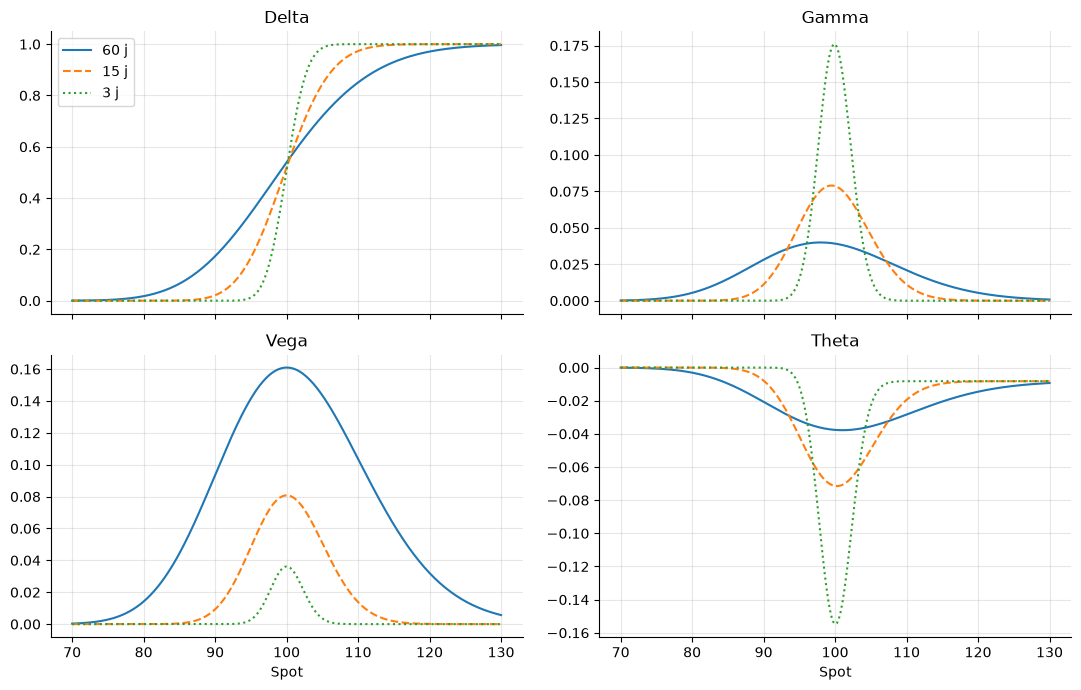

In [6]:
S = np.linspace(70, 130, 241)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for days, ls in [(60, "-"), (15, "--"), (3, ":")]:
    out = g.greeks(S, 100, days / 365, 0.03, 0.25, "call")
    for ax, name in zip(axes.flat, ["delta", "gamma", "vega", "theta"]):
        ax.plot(S, out[name], ls, label=f"{days} j")
        ax.set_title(name.capitalize())
for ax in axes[1]:
    ax.set_xlabel("Spot")
axes[0, 0].legend()
plt.tight_layout()

## 5. Application : couvrir un book

Tu as vendu **50 calls** (multiplicateur 100). Combien d'actions pour être *delta-neutral* ?

In [7]:
contracts, multiplier = -50, 100
d = float(g.greeks(**P, kind="call")["delta"])
position_delta = contracts * multiplier * d
print(f"delta d'un call : {d:.3f}")
print(f"delta de la position : {position_delta:,.0f} actions")
print(f"→ pour être delta-neutral : {'acheter' if -position_delta > 0 else 'vendre'} {abs(position_delta):,.0f} actions")

delta d'un call : 0.351
delta de la position : -1,756 actions
→ pour être delta-neutral : acheter 1,756 actions


### À toi de jouer

1. Reprends la cellule de couverture avec un **put** (`kind="put"`) : le signe de la couverture change-t-il ? Pourquoi ?
2. Fais passer la maturité de 60 à 3 jours : que devient le gamma d'une option ATM ? (Compare avec la leçon Gamma.)
3. Écris la vérification par différences finies pour le **rho** d'un put et compare.